# Pruning comparison: EasyEP vs HOPE vs REAP

Compares evaluation summaries at prune percentages 20–45%.

**Note:** the unpruned baselines differ between the two eval folders (EasyEP runs vs HOPE/REAP runs), so raw
perplexity is not directly comparable across them. The *relative* perplexity increase (vs. each run's own
original model) is the fairer comparison. KL and top-1 agreement are already measured against each run's own original.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..")
PCTS = [20, 25, 30, 35, 40, 45]

def easyep_dir(pct):
    return ROOT / f"easy_ep_eval/easyep_output_{pct}/kaggle/working/easyep-out/eval"

def hope_reap_dir(pct):
    return ROOT / f"hope_reap_evals/hope_{pct}"

## Load summary metrics

In [2]:
rows = []
for pct in PCTS:
    easy = json.loads((easyep_dir(pct) / "summary.json").read_text())
    hr = json.loads((hope_reap_dir(pct) / "summary.json").read_text())
    for method, summary, key in [
        ("EasyEP", easy, f"pruned-easyep-{pct}pct"),
        ("HOPE", hr, "pruned-hope"),
        ("REAP", hr, "pruned-reap"),
    ]:
        m = summary[key]
        base_ppl = summary["original"]["perplexity"]
        rows.append({
            "method": method,
            "prune_pct": pct,
            "baseline_ppl": base_ppl,
            "perplexity": m["perplexity"],
            "ppl_increase_pct": 100 * (m["perplexity"] - base_ppl) / base_ppl,
            "kl": m["kl"],
            "top1_agreement": m["top1_agreement"],
        })

df = pd.DataFrame(rows)
df.round(3)

,method,prune_pct,baseline_ppl,perplexity,ppl_increase_pct,kl,top1_agreement
0,EasyEP,20,46.392,51.090,10.127,0.179,0.811
1,HOPE,20,40.196,42.670,6.153,0.078,0.839
2,REAP,20,40.196,42.857,6.619,0.096,0.818
3,EasyEP,25,46.392,51.274,10.523,0.219,0.785
4,HOPE,25,40.196,44.874,11.638,0.128,0.786
5,REAP,25,40.196,43.594,8.451,0.152,0.776
6,EasyEP,30,46.392,53.451,15.217,0.272,0.758
7,HOPE,30,40.196,46.939,16.774,0.181,0.746
8,REAP,30,40.196,44.620,11.004,0.192,0.745
9,EasyEP,35,46.392,53.420,15.150,0.277,0.720


## Side-by-side tables

In [3]:
for metric in ["perplexity", "ppl_increase_pct", "kl", "top1_agreement"]:
    print(f"\n{metric}")
    display(df.pivot(index="prune_pct", columns="method", values=metric).round(3))


perplexity


method,EasyEP,HOPE,REAP
prune_pct,,,
20,51.090,42.670,42.857
25,51.274,44.874,43.594
30,53.451,46.939,44.620
35,53.420,48.359,47.084
40,61.541,53.157,50.480
45,66.890,57.535,55.350



ppl_increase_pct


method,EasyEP,HOPE,REAP
prune_pct,,,
20,10.127,6.153,6.619
25,10.523,11.638,8.451
30,15.217,16.774,11.004
35,15.150,20.305,17.135
40,32.655,32.242,25.583
45,44.186,43.135,37.697



kl


method,EasyEP,HOPE,REAP
prune_pct,,,
20,0.179,0.078,0.096
25,0.219,0.128,0.152
30,0.272,0.181,0.192
35,0.277,0.234,0.257
40,0.442,0.353,0.343
45,0.561,0.438,0.435



top1_agreement


method,EasyEP,HOPE,REAP
prune_pct,,,
20,0.811,0.839,0.818
25,0.785,0.786,0.776
30,0.758,0.746,0.745
35,0.720,0.716,0.718
40,0.661,0.671,0.660
45,0.629,0.631,0.627


## Plots

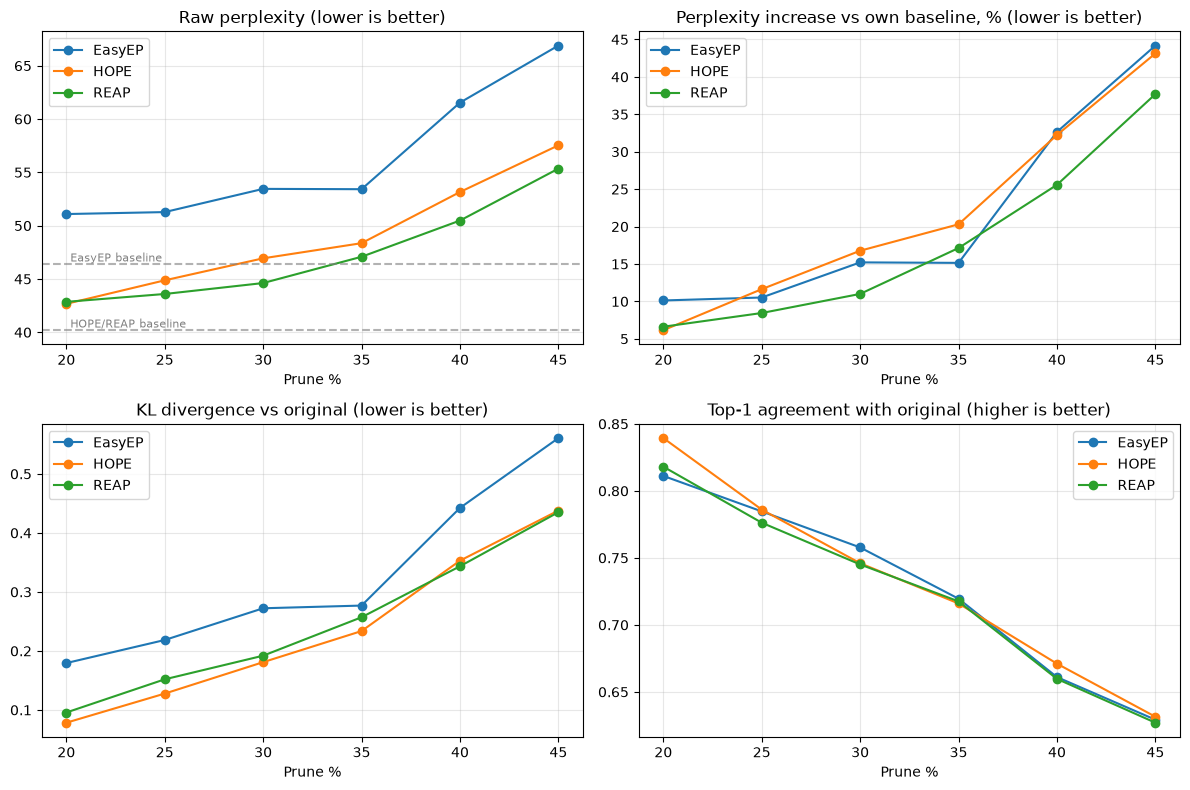

In [4]:
metrics = [
    ("perplexity", "Raw perplexity (lower is better)"),
    ("ppl_increase_pct", "Perplexity increase vs own baseline, % (lower is better)"),
    ("kl", "KL divergence vs original (lower is better)"),
    ("top1_agreement", "Top-1 agreement with original (higher is better)"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (metric, title) in zip(axes.flat, metrics):
    for method, g in df.groupby("method"):
        ax.plot(g["prune_pct"], g[metric], marker="o", label=method)
    ax.set_title(title)
    ax.set_xlabel("Prune %")
    ax.grid(alpha=0.3)
    ax.legend()

# show each folder's baseline on the raw perplexity plot
for base, label in [(df.loc[df.method == "EasyEP", "baseline_ppl"].iloc[0], "EasyEP baseline"),
                    (df.loc[df.method == "HOPE", "baseline_ppl"].iloc[0], "HOPE/REAP baseline")]:
    axes[0, 0].axhline(base, linestyle="--", color="gray", alpha=0.6)
    axes[0, 0].text(PCTS[0], base, f" {label}", va="bottom", fontsize=8, color="gray")

plt.tight_layout()
plt.show()

## Sample generations

Change `PCT` and `PROMPT_IDX` to inspect other outputs.

In [7]:
PCT = 30
PROMPT_IDX = 0

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

easy_gens = read_jsonl(easyep_dir(PCT) / "generations.jsonl")[PROMPT_IDX]
hr_gens = read_jsonl(hope_reap_dir(PCT) / "generations.jsonl")[PROMPT_IDX]

print("PROMPT:\n", easy_gens["prompt"], "\n")
for label, entry in [
    ("Original (EasyEP run)", easy_gens["original"]),
    (f"EasyEP {PCT}%", easy_gens[f"pruned-easyep-{PCT}pct"]),
    ("Original (HOPE/REAP run)", hr_gens["original"]),
    (f"HOPE {PCT}%", hr_gens["pruned-hope"]),
    (f"REAP {PCT}%", hr_gens["pruned-reap"]),
]:
    print(f"=== {label}  (ppl={entry['perplexity']:.2f})")
    print(entry["generation"].strip(), "\n")

PROMPT:
 Write a product description for the following product. Name: Velqorin SlateNote Reader. Specifications: 7.8-inch matte e-paper display; adjustable warm front light; 32 GB internal storage; 3-week typical battery life; 198 g weight. Target audience: independent translators who read long manuscripts while travelling between client appointments. Product description: 

=== Original (EasyEP run)  (ppl=62.45)
The Velqorin SlateNote Reader is a slate-style e-reader designed for translators who need to read long manuscripts while travelling between client appointments. The Velqorin SlateNote Reader has a 7.8-inch matte e-paper display, which is easy on the eyes and can be read in direct sunlight. The Velqorin SlateNote Reader has a warm front light that can be adjusted to suit the user's needs. The Velqorin SlateNote Reader has 32 GB of internal storage, which is enough for most users. The Velqorin SlateNote Reader has a battery life of 3 

=== EasyEP 30%  (ppl=77.01)
The SlateNote Re